# Numerical Method for Solving Linear Systems of Equations

## System of Linear Equations

Given a matrix $n\times n$ matrix and a vector $b$, the goal is to solve the equation

$$
Ax = b.
$$

- Some algorithms to solve the system
- Apply the idea to image processing
- Understand the complexity of solving the system of linear equations.

## Main Theme:

- Computational Efficiency: How quickly can we solve a system of linear equations?
- Computational Cost: How many FLOPs (Floating-point operations: $+$, $-$, $\times$, $\div$) does the algorithm require so solve a system of equations?
- Accuracy: How close is the computed solution to the exact solution?
- Numerical stability: Does the algorithm amplify or reduce the error by rounding or finite precision arithmetic of floating point operations?

**Example:** Let $x$ be an image, and we can apply a transformation, $A$ to blur the image. Then to recover the original image, we have to solve $Ax = b$ for the original $x$.

Basically we can use Toeplitz matrix to blur the image

$$
A = \begin{pmatrix}
a_1 & a_2 & \cdots & 0 \\
a_2 & a_1 & a_2 & 0 \\
\vdots & \ddots & \ddots & \vdots \\
0 & 0 & \cdots & a_1
\end{pmatrix}
$$

a) Write a function to construct a $10 \times 10$ Toeplitz matrix with entries are 1.0, 0.9, 0.8 on the diagonal.

In [27]:
import numpy as np

from Homework.Guthrie_Homework05_Math311 import step_size

In [28]:
# construct A manually
# zero matrix
A = np.zeros((10, 10))

In [29]:
print(A)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [30]:
# set 1.0 on the 1st diagonal
for i in range(10):
    A[i, i] = 1.0

In [31]:
print(A)

[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [32]:
# set 0.9 on 2nd diagonals
for i in range(9):
    A[i, i + 1] = 0.9
    A[i + 1, i] = 0.9

In [33]:
print(A)

[[1.  0.9 0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.9 1.  0.9 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.9 1.  0.9 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.9 1.  0.9 0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.9 1.  0.9 0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.9 1.  0.9 0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.9 1.  0.9 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.9 1.  0.9 0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.9 1. ]]


In [34]:
# set 0.8 on the 3rd diagonals
for i in range(8):
    A[i, i + 2] = 0.8
    A[i + 2, i] = 0.8

In [35]:
print(A)

[[1.  0.9 0.8 0.  0.  0.  0.  0.  0.  0. ]
 [0.9 1.  0.9 0.8 0.  0.  0.  0.  0.  0. ]
 [0.8 0.9 1.  0.9 0.8 0.  0.  0.  0.  0. ]
 [0.  0.8 0.9 1.  0.9 0.8 0.  0.  0.  0. ]
 [0.  0.  0.8 0.9 1.  0.9 0.8 0.  0.  0. ]
 [0.  0.  0.  0.8 0.9 1.  0.9 0.8 0.  0. ]
 [0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8 0. ]
 [0.  0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8]
 [0.  0.  0.  0.  0.  0.  0.8 0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.  0.  0.8 0.9 1. ]]


In [36]:
# Write a function to return a Toeplitz matrix
def gen_toeplitz_mat(n, v):
    # n: the size of the matrix
    # v: vector which contains the values on the diagonal
    A = np.zeros((n,n))
    k = len(v)
    # if v has more than n elements, we raise the error
    if k > n:
        raise ValueError('Too many values for v')
    for j in range(k):
        for i in range(n - j):
            A[i, i + j] = v[j]
            A[i + j, i] = v[j]

    return A

In [37]:
n = 10
v = [1.0, 0.9, 0.8]
A = gen_toeplitz_mat(n, v)
print(A)

[[1.  0.9 0.8 0.  0.  0.  0.  0.  0.  0. ]
 [0.9 1.  0.9 0.8 0.  0.  0.  0.  0.  0. ]
 [0.8 0.9 1.  0.9 0.8 0.  0.  0.  0.  0. ]
 [0.  0.8 0.9 1.  0.9 0.8 0.  0.  0.  0. ]
 [0.  0.  0.8 0.9 1.  0.9 0.8 0.  0.  0. ]
 [0.  0.  0.  0.8 0.9 1.  0.9 0.8 0.  0. ]
 [0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8 0. ]
 [0.  0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8]
 [0.  0.  0.  0.  0.  0.  0.8 0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.  0.  0.8 0.9 1. ]]


In [ ]:
gen_toeplitz_mat(4, v=[1.0, 0.9, 0.8, 0.7, 0.6])

**Example:** Create an image with text: "ALABAMA"

In [39]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.


In [40]:
from PIL import Image, ImageDraw, ImageFont

In [41]:
# create an empty image
w = 300
h = 50

In [42]:
img = Image.new('L', (w, h), color=255)

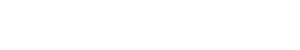

In [43]:
img

In [44]:
pen = ImageDraw.Draw(img)
font = ImageFont.load_default(size=36)
pen.text((0,0), "ALABAMA", fill=0, font=font)

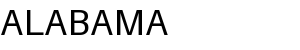

In [45]:
img

In data science (scientific computing), an image is just a matrix of numbers!

In [46]:
img_arr = np.array(img)

In [47]:
print(img_arr)

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]


In [48]:
# We will blur this image using a Toeplitz matrix
# - flatten the image
# - create a matrix
# - multiply matrix
# convert the image into a vector
x = img_arr.flatten()

In [49]:
x

array([255, 255, 255, ..., 255, 255, 255], shape=(15000,), dtype=uint8)

In [50]:
n = x.shape[0]

In [51]:
A = gen_toeplitz_mat(n, v=[1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3])

In [52]:
print(A.shape)

(15000, 15000)


In [53]:
print(A[:10,:10])

[[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.  0. ]
 [0.9 1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0. ]
 [0.8 0.9 1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3]
 [0.7 0.8 0.9 1.  0.9 0.8 0.7 0.6 0.5 0.4]
 [0.6 0.7 0.8 0.9 1.  0.9 0.8 0.7 0.6 0.5]
 [0.5 0.6 0.7 0.8 0.9 1.  0.9 0.8 0.7 0.6]
 [0.4 0.5 0.6 0.7 0.8 0.9 1.  0.9 0.8 0.7]
 [0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  0.9 0.8]
 [0.  0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  0.9]
 [0.  0.  0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]]


In [54]:
x_blur = A@x

In [55]:
print(x_blur.shape)

(15000,)


In [56]:
x_blur[:10]

array([1326. , 1555.5, 1759.5, 1938. , 2091. , 2218.5, 2320.5, 2397. ,
       2397. , 2397. ])

In [57]:
# reshape to the original size 300x50
blur_image = x_blur.reshape(50, 300)

In [58]:
import matplotlib.pyplot as plt

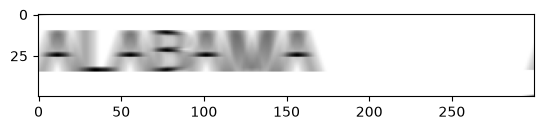

In [59]:
# blur_img is a matrix, not an image!
fig, ax = plt.subplots()
ax.imshow(blur_image, cmap='gray')
# set cmap=gray to turn the image to gray scale

## How to solve a system of linear equations numerically?

**Theorem:** If $A$ is invertable, $\det(A)\ne 0$, then the system $Ax=b$ has exact solution
$$
x = A^{-1}b.
$$

Getting the exact solutions is not efficient in scientific computing, so we have to approximate the solution with better accuracy.

*Case 1:* Simple cases: Triangular system.

## Forward Substitution for lower triangular system

Let $L$ be a lower triangular matrix.

$$
L = \begin{bmatrix}
l_{11} & 0 & \cdots & 0 \\
l_{21} & l_{22} & 0 & \cdots \\
\vdots & \vdots & \ddots & \vdots \\
1_{n1} & \cdots & \cdots & l_{m}
\end{bmatrix}
$$

($L$ has at most $\frac{n(n+1)}{2}$ non-zero entries)
and a vector
$$
b = [b_1, \ldots, b_n]
$$

Now we want to solve
$$
\begin{aligned}
&l_{11}x_1 = b_1 \\
&l_{21}x_1+l_{22}x_2 = b_2 \\
&\cdots \\
&l_{n1}x_1+l_{n2}x_2+\cdots+l_{nn}x_n=b_n \\
\end{aligned}
$$

Suppose $l_{ii}\ne 0$ for all $i$.

We can solve for $x_i$ as follows
$$
x_i = \frac{b_i - \sum_{j=1}^{i-1}l_{ij}*x_j}{l_{ii}}
$$

We can analyze the nnumbr of FLOPs (FLoating point operations: $+, -, \div, \times$)

To solve for $x_1$ we need $1$ FLOP, for $x_2$ we need $3$ FLOPs, $\cdots$, for $x_n$ we need $2(n-1)+1 = 2n-1$ FLOPs.

Total we have $1 + 3 + \cdots + 2n-1 = n^2$ FLOPs

So the cost of solving a system fo linear equations in the lower triangular case is $n^2$. There are two things we need to do:

- How can we solve this system? (Implement an algorithm to solve it)
- Do analysis to confirm the cost of the algorithm.

In [60]:
# get the idea to obtain general formula
for n in range(1, 21):
    s = 0
    for i in range(1, n + 1):
        s += 2*i - 1
    print(f"n = {n}, s = {s}")

n = 1, s = 1
n = 2, s = 4
n = 3, s = 9
n = 4, s = 16
n = 5, s = 25
n = 6, s = 36
n = 7, s = 49
n = 8, s = 64
n = 9, s = 81
n = 10, s = 100
n = 11, s = 121
n = 12, s = 144
n = 13, s = 169
n = 14, s = 196
n = 15, s = 225
n = 16, s = 256
n = 17, s = 289
n = 18, s = 324
n = 19, s = 361
n = 20, s = 400


**Implement the algorithm**

In [61]:
import numpy as np

In [62]:
def forward_sub(L, b):
    """
    Solve Lx = b
    return x as float
    """
    # init an empty vector
    x = np.empty_like(b).astype(float)
    n = len(b)
    if L.shape != (n,n):
        raise ValueError('The matrix L does not have the same size as b!')
    for i in range(n):
        if i == 0:
            x[i] = b[i] / L[i, i]
        else:
            x[i] = (b[i] - np.dot(x[:i], L[i, :i])) / L[i, i]
    return x

In [63]:
# test is
L = np.array([
    [1, 0],
    [1, 2]
])
b = np.array([1, 2])
forward_sub(L, b)

array([1. , 0.5])

In [64]:
# test to make sure it is right!
# generate random matrix
n = 20
L = np.tril(np.random.normal(loc=1.5, scale=0.8, size=(n, n)))
b = np.random.normal(loc=1.5, scale=1.2, size=n)
print(L.shape)
print(b.shape)
# solve the system Lx = b
x = forward_sub(L, b)
# use numpy to solve it
x_np = np.linalg.solve(L, b)
# make sure x and x_np are `equal`.
np.allclose(x_np, x)

(20, 20)
(20,)


True

**Cost Analysis:** Use the algorithm to solve random systems, record the running time and plot against the size $n$. We wish to obtain $O(n^2)$.

In [76]:
n_vals = np.arange(1000, 4_001, 100)

In [77]:
exc_time = []

In [78]:
import time

In [79]:
for n in n_vals:
    # generate matrix
    L = np.tril(np.random.normal(loc=1.5, scale=0.8, size=(n, n)))
    b = np.random.normal(loc=0, scale=1.2, size=n)
    # solve it
    start_time = time.time()
    # x = forward_sub(L, b)
    x = np.linalg.solve(L, b)
    end_time = time.time()
    exc_time.append(end_time - start_time)

**Theoretical Result:** We know complexity of solving the triangluar system is $n^2$. It means
$$
cost = O(n^2).
$$

$t \approx C*n^2$. Therefore
$$
\ln(t) \approx \ln(C) + 2 * \ln(n)
$$

When we plot the running time vs the size of matrix in log scale, we expect to get the slope = 2 for the chart.

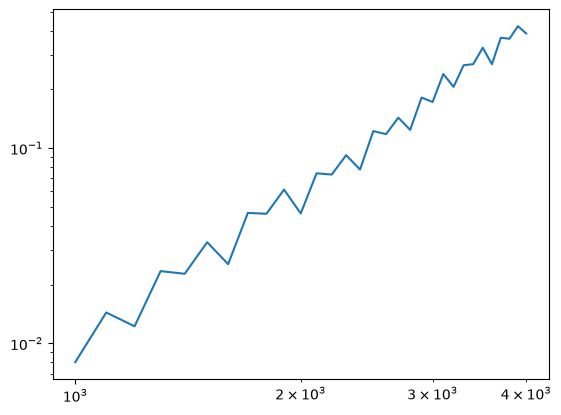

In [80]:
fig, ax = plt.subplots()
plt.loglog(n_vals, exc_time)
plt.show()

In [91]:
# find the slope of this data
# use Numpy polyfit function to find the slope and intercept
# set deg = 1 as it is a line
slope, intercept = np.polyfit(np.log(n_vals), np.log(exc_time), deg=1)

In [92]:
print(slope)

2.7539982288628635


In [93]:
# computed fitting values for the line
fitted_y = np.exp(intercept + slope * np.log(n_vals))

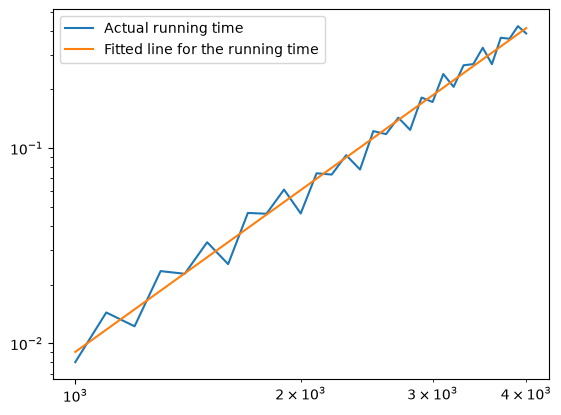

In [94]:
fig, ax = plt.subplots()

ax.loglog(n_vals, exc_time, label='Actual running time')
ax.loglog(n_vals, fitted_y, label='Fitted line for the running time')

ax.legend()
plt.show()

Based on the first experiment, the slope is to far away from $2$. So we should find a better approach.

- Select the sizes of matrix more uniformly
- Try wuth `forward_sub` or `solve_triangular` from scipy (install scipy)
- Compare the running time of these functions vs the theoretical result.

In [102]:
# geometric sequence in Numpy
np.geomspace(1000, 5000, 100).astype(int)

array([1000, 1016, 1033, 1049, 1067, 1084, 1102, 1120, 1138, 1157, 1176,
       1195, 1215, 1235, 1255, 1276, 1297, 1318, 1339, 1361, 1384, 1406,
       1429, 1453, 1477, 1501, 1526, 1551, 1576, 1602, 1628, 1655, 1682,
       1709, 1738, 1766, 1795, 1824, 1854, 1885, 1916, 1947, 1979, 2011,
       2044, 2078, 2112, 2147, 2182, 2217, 2254, 2291, 2328, 2366, 2405,
       2445, 2485, 2526, 2567, 2609, 2652, 2695, 2739, 2784, 2830, 2876,
       2924, 2971, 3020, 3070, 3120, 3171, 3223, 3276, 3330, 3384, 3440,
       3496, 3553, 3612, 3671, 3731, 3792, 3854, 3918, 3982, 4047, 4113,
       4181, 4249, 4319, 4390, 4462, 4535, 4609, 4685, 4761, 4840, 4919,
       5000])

In [106]:
# remove all duplicates
n_vals = np.unique(np.geomspace(1000, 5000, 200).astype(int))

In [107]:
print(n_vals.shape)

(200,)


In [108]:
n_vals

array([1000, 1008, 1016, 1024, 1032, 1041, 1049, 1058, 1066, 1075, 1084,
       1093, 1101, 1110, 1119, 1128, 1138, 1147, 1156, 1166, 1175, 1185,
       1194, 1204, 1214, 1224, 1234, 1244, 1254, 1264, 1274, 1284, 1295,
       1305, 1316, 1327, 1337, 1348, 1359, 1370, 1381, 1393, 1404, 1415,
       1427, 1438, 1450, 1462, 1474, 1486, 1498, 1510, 1522, 1535, 1547,
       1560, 1572, 1585, 1598, 1611, 1624, 1637, 1651, 1664, 1678, 1691,
       1705, 1719, 1733, 1747, 1761, 1775, 1790, 1804, 1819, 1834, 1849,
       1864, 1879, 1894, 1909, 1925, 1940, 1956, 1972, 1988, 2004, 2021,
       2037, 2054, 2070, 2087, 2104, 2121, 2138, 2156, 2173, 2191, 2209,
       2227, 2245, 2263, 2281, 2300, 2318, 2337, 2356, 2375, 2395, 2414,
       2434, 2454, 2473, 2494, 2514, 2534, 2555, 2576, 2596, 2618, 2639,
       2660, 2682, 2704, 2726, 2748, 2770, 2793, 2815, 2838, 2861, 2884,
       2908, 2931, 2955, 2979, 3003, 3028, 3052, 3077, 3102, 3127, 3153,
       3178, 3204, 3230, 3256, 3283, 3310, 3336, 33

In [109]:
# write a loop to measure the running time
run_time = []
for n in n_vals:
    L = np.random.normal(loc=0, scale=1, size=(n, n))
    # convert it to a triangular matrix
    L = np.tril(L)
    # fill wht diagonal with large values (use n on the diagonal)
    np.fill_diagonal(L, n)
    b = np.random.normal(loc=0, scale=1, size=n)
    start_time = time.time()
    x = forward_sub(L, b)
    end_time = time.time()
    run_time.append(end_time - start_time)

In [110]:
slope, intercept = np.polyfit(np.log(n_vals), np.log(run_time), deg=1)

In [111]:
print(slope)

1.506903272340352


In [112]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [113]:
# use solve_triangular from scipy
from scipy.linalg import solve_triangular

In [114]:
run_time = []
for n in n_vals:
    L = np.random.normal(loc=0, scale=1, size=(n, n))
    # convert it to a triangular matrix
    L = np.tril(L)
    # fill wht diagonal with large values (use n on the diagonal)
    np.fill_diagonal(L, n)
    b = np.random.normal(loc=0, scale=1, size=n)
    start_time = time.time()
    x = solve_triangular(L, b, lower=True)
    end_time = time.time()
    run_time.append(end_time - start_time)

In [115]:
slope, intercept = np.polyfit(np.log(n_vals), np.log(run_time), deg=1)

In [117]:
print(slope)

2.440589648678126


In [118]:
fitted_y = np.exp(intercept + slope * np.log(n_vals))

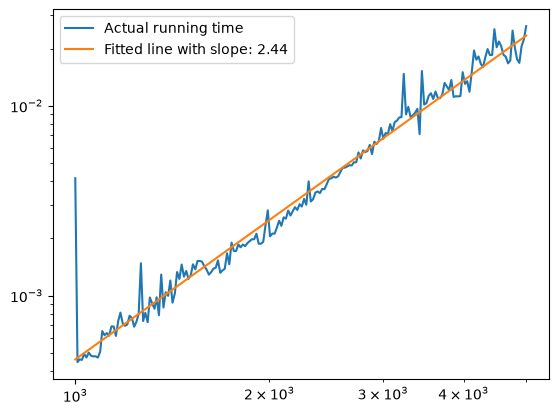

In [125]:
fig, ax = plt.subplots()
ax.loglog(n_vals, run_time, label='Actual running time')
ax.loglog(n_vals, fitted_y, label=f'Fitted line with slope: {slope:.2f}')
ax.legend()

plt.show()

# LU Decomposition

## Solve a general system $Ax = b$.

So far if $L$ is a lower triangular matrix, or $U$ is an upper triangular matrix, we can solve the system
$$
Lx = b
$$
or
$$
Uy = d.
$$

The cost for the lower or upper is $O(n^2)$.

Now for general matrix, we wish to find $L$ and $U$ such that $A=LU$.
Then $Ax = b$ is equivalent to
$$
LUx = b
$$

Set $y = Ux$, then we have two systems
$$
Ly = b
$$
and
$$
Ux = y
$$

So we can solve $Ly = b$ for $y$ first, then plugin $y$ into
$$
Ux = y
$$
and solve for $x$.

**Theorem:** For any matrix $A$, there exists $P, L, U$ such that
$$
A = PLU,
$$
where
- $P$ is a permutation matrix (swap rows and columns from the identity matrix)
- $L$ is the lower triangular matrix
- $U$ is the upper triangular matrix

We can skip $P$ for now, and just try to find $L$ and $U$  such that $A = LU$.

The form of these matrices
$$
A = \begin{bmatrix}
a_{11} & a_{12} & \cdots & a_{1n} \\
a_{21} & a_{22} & \cdots & a_{n2} \\
\vdots & \vdots & \ddots & \vdots \\
a_{n1} & a_{n2} & \cdots & a_{nn}
\end{bmatrix}
$$

$$
L = \begin{bmatrix}
1 & 0 & \cdots & 0 \\
l_{21} & 1 & \cdots & 0 \\
\vdots & \vdots & \ddots & 0 \\
1_{n1} & 1_{n2} & \cdots & 1
\end{bmatrix}
$$

$$
U = \begin{bmatrix}
u_{11} & u_{12} & \cdots & u_{1n} \\
0 & u_{22} & \cdots & u_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \cdots & u_{nn}
\end{bmatrix}
$$

We have 3 equations to determine $L$ and $U$:

$$
[u_{11}, U_{12}] = [a_{11}, A_{12}],
$$

$$
\begin{bmatrix}
1 \\
L_{21}
\end{bmatrix}
=
\frac{1}{u_{11}}
\begin{bmatrix}
a_{11} \\
a_{21}
\end{bmatrix}
$$

$$
M = A_{22} - L_{21}*U_{12}.
$$

In [1]:
import numpy as np

In [22]:
# Example
A = np.array([
    [2, 3, 4, 5],
    [2, 4, 6, 6],
    [2, 4, 9, 7],
    [2, 4, 9, 9]
])

In [23]:
# find LU decomposition
# make a copy of A
M = A.copy()
# init the empty matrix
n = A.shape[0]
L = np.zeros((n, n))
U = np.zeros((n, n))

In [24]:
# 1st row of U = 1st row of M
U[0,:] = M[0,:]
# 1st col of L = 1/U[0,0] * 1st col of M
L[:, 0] = (1/U[0,0]) * M[:,0]

In [25]:
# Update the M
M[1:, 1:] = M[1:, 1:] - np.outer(L[1:, 0], U[0, 1:])
# Zero out 1st row and col of M
M[0, :] = 0
M[:, 0] = 0
print(M)

[[0 0 0 0]
 [0 1 2 1]
 [0 1 5 2]
 [0 1 5 4]]


In [26]:
print(M)
print(L)
print(U)

[[0 0 0 0]
 [0 1 2 1]
 [0 1 5 2]
 [0 1 5 4]]
[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]]
[[2. 3. 4. 5.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [27]:
# explain the outer product
u = np.array([1, 2, 3])
v = np.array([2, 1, 2])
print(np.outer(u, v))

[[2 1 2]
 [4 2 4]
 [6 3 6]]


Implement the LU Decomposition from scratch.

Given a matrix $A$ size $n \times n$, we find two matrices $L$ and $U$ such that
$$
A = LU
$$
where $L$ is the lower triangular matrix with ones on the diagonal, and $U$ is an upper triangular matrix.

In [1]:
import numpy as np

In [10]:
def lu_decomposition(A):
    m, n = A.shape
    if m != n:
        raise ValueError("THe matrix must be square!")
    # make a copy of A
    M = A.copy().astype(float)
    # create empty matrices
    L = np.zeros((n, n))
    U = np.zeros((n, n))

    # loop over the rows
    for i in range(n):
        # copy the ith row from i->n to U
        U[i, i:] = M[i, i:]
        L[i:, i] = M[i:, i] / M[i, i]
        # update the matrix M block
        # M -> M - outer(L_col, U_row)
        # we only update if i < n-1
        if i < n-1:
            M[i+1:, i+1:] = M[i+1:, i+1:] - np.outer(L[i+1:, i], U[i, i+1:])
    return L, U

In [3]:
# Test this function
A = np.array([
    [2, 3, 4, 5],
    [2, 4, 6, 6],
    [2, 4, 9, 7],
    [2, 4, 9, 9]
])

In [5]:
L, U = lu_decomposition(A)

In [6]:
print(L)

[[1. 0. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 1. 0.]
 [1. 1. 1. 1.]]


In [7]:
print(U)

[[2. 3. 4. 5.]
 [0. 1. 2. 1.]
 [0. 0. 3. 1.]
 [0. 0. 0. 2.]]


In [9]:
# check to make sure L*U=A
np.allclose(L@U, A)

True

In [11]:
# create a function to generate a random lower matrix
def random_lower_matrix(n, low=-3, high=3):
    A = np.random.randint(low=low, high=high, size=(n, n))
    A = np.tril(A)
    # deal with situation when A[i,i] = 0.
    for i in range(n):
        if A[i,i] == 0:
            A[i,i] = np.random.randint(1, high)

    return A

In [12]:
# construct a matrix A to test with our LU decomp.
n = 10
A = random_lower_matrix(n, low=-4, high=4)
B = random_lower_matrix(n, low=-4, high=4)
C = A@B.T

In [13]:
L, U = lu_decomposition(C)

In [14]:
print(L)

[[ 1.          0.          0.          0.          0.          0.
   0.          0.          0.          0.        ]
 [-1.33333333  1.          0.          0.          0.          0.
   0.          0.          0.          0.        ]
 [-1.33333333 -0.66666667  1.          0.          0.          0.
   0.          0.          0.          0.        ]
 [-1.33333333 -0.33333333 -0.          1.          0.          0.
   0.          0.          0.          0.        ]
 [-0.66666667 -0.          1.          1.          1.          0.
   0.          0.          0.          0.        ]
 [-1.33333333 -1.33333333  2.          1.          1.          1.
   0.          0.          0.          0.        ]
 [-1.33333333  0.33333333 -0.         -3.         -0.66666667  0.5
   1.          0.          0.          0.        ]
 [-0.33333333  0.66666667  4.          3.         -1.          1.
  -0.          1.          0.          0.        ]
 [ 0.33333333 -0.66666667  4.          2.         -0.33333333 -

In [15]:
print(U)

[[  6.   9.  -9.   9.  -9.   9. -12.   0.   3.  -6.]
 [  0. -12.  -3.   9.   0.   9.   6.   9. -12.  -3.]
 [  0.   0.  -3.   4.   3.  -3.   1.  -3.   1.   4.]
 [  0.   0.   0.  -2.   2.   4.   1.  -3.  -3.  -1.]
 [  0.   0.   0.   0.   9.  -9.   6.   3.  -6.   9.]
 [  0.   0.   0.   0.   0.   6.   6.  -4.   2.  -4.]
 [  0.   0.   0.   0.   0.   0.  -1.   1.  -1.  -3.]
 [  0.   0.   0.   0.   0.   0.   0.  -2.  -6.   6.]
 [  0.   0.   0.   0.   0.   0.   0.   0.  -2.  -3.]
 [  0.   0.   0.   0.   0.   0.   0.   0.   0.  16.]]


In [16]:
np.allclose(C, L@U)

True

**Theorem:** The complexity of `$LU$ decomposition` is $O(n^3)$. Therefore the complexity for solving a system of linear equations is the same, $O(n^3)$.

Use Python to demonstrate the complexity of `solving system of linear equations`.

In [48]:
start_size = 1000
end_size = 4000
step_size = 100

In [49]:
sizes = np.arange(start_size, end_size, step_size)

In [50]:
print(sizes.shape)

(30,)


In [51]:
import time
import matplotlib.pyplot as plt

In [52]:
run_time = []

In [53]:
# main loop
for n in sizes:
    # generate random matrix
    A = np.random.normal(loc=0, scale=1.5, size=(n, n))
    b = np.random.normal(size=n)
    start_time = time.time()
    # solve the system Ax = b
    x = np.linalg.solve(A, b)
    end_time = time.time()
    run_time.append(end_time - start_time)

In [54]:
# compute slope, intercept
slope, intercept = np.polyfit(np.log(sizes), np.log(run_time), deg=1)
print(slope)

2.593189003817267


In [55]:
# compute the fitted line
y_hat = np.exp(slope * np.log(sizes) + intercept)

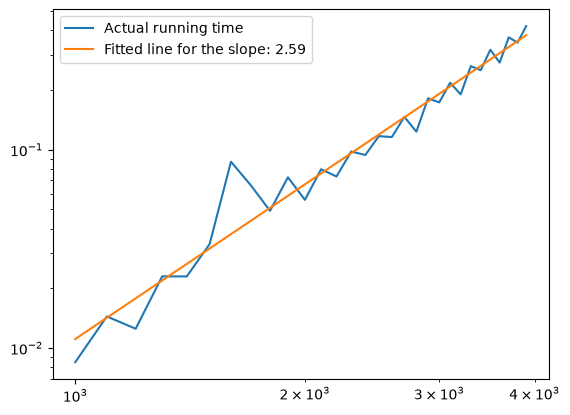

In [56]:
fig, ax = plt.subplots()
ax.loglog(sizes, run_time, label="Actual running time")

ax.loglog(sizes, y_hat, label=f"Fitted line for the slope: {slope:.2f}")

ax.legend()

plt.show()